In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro, levene, f_oneway, kruskal, tukey_hsd, spearmanr

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Đường dẫn thư mục dữ liệu
PROCESSED = Path("DATA_PROCESS/data processed") if Path("DATA_PROCESS/data processed").exists() else Path("/content/drive/MyDrive/[LTPTDL] Đồ án/data processed")

pl_file = PROCESSED / "pl.csv"

if pl_file.exists():
    pl = pd.read_csv(pl_file)
    print("-> Đã tải thành công bảng P&L từ file:", pl_file)
else:
    # Nếu chưa có pl.csv, tích hợp từ 10 bảng đã làm sạch theo đúng quy trình 2.2 & 2.3
    FILES = ["Fact", "Calendar", "Business Line", "Group", "Subgroup", "Channel", "Region", "Headlines", "KPI", "Ratios"]
    tables = {f: pd.read_csv(PROCESSED / f"{f}.csv", dtype=str, encoding="utf-8-sig") for f in FILES}
    
    df = tables["Fact"].copy()
    calendar = tables["Calendar"].copy()
    df["Amount"] = df["Amount, $"].astype(float)
    df["Date"] = pd.to_datetime(df["Date"])
    calendar["Date"] = pd.to_datetime(calendar["Date"])
    df = df.rename(columns={"Business Line ID": "BL_ID", "Business Line Name": "BL_Name", "Subgroup ID": "Subgroup_ID", "Group ID": "Group_ID", "Revenue or expense": "RevExp"})
    
    sg = tables["Subgroup"][["Subgroup ID", "Subgroup"]].astype(str)
    gr = tables["Group"][["Group ID", "Group"]].astype(str)
    sg.columns = ["Subgroup_ID", "Subgroup_Name"]
    gr.columns = ["Group_ID", "Group_Name"]
    
    integrated = (
        df.merge(calendar[["Date", "Year", "Quarter", "Month", "Month in text"]],
                 on="Date", how="left", validate="many_to_one")
          .merge(sg, on="Subgroup_ID", how="left", validate="many_to_one")
          .merge(gr, on="Group_ID", how="left", validate="many_to_one")
    ).rename(columns={"BL_Name": "Business_Line"})
    
    data = integrated[[
        "TransactionID", "Date", "Year", "Month", "Quarter",
        "Business_Line", "Subgroup_ID", "Group_ID",
        "Amount", "Channel", "Region"
    ]].copy()
    
    data["Amount_abs"] = data["Amount"].abs()
    data["Financial_Type"] = data["Group_ID"].map({
        "1": "Revenue", "2": "Opex", "3": "COGS", "4": "Interest_Tax"
    })
    
    pl = data.pivot_table(
        index=["Month", "Quarter", "Business_Line"],
        columns="Financial_Type", values="Amount_abs",
        aggfunc="sum", fill_value=0
    ).reset_index()
    pl.columns.name = None
    
    pl["Gross_Profit"] = pl["Revenue"] - pl["COGS"]
    pl["GP_Margin"] = pl["Gross_Profit"] / pl["Revenue"]
    pl["Opex_Ratio"] = pl["Opex"] / pl["Revenue"]
    print("-> Đã tổng hợp thành công bảng P&L từ dữ liệu làm sạch!")

display(pl.head(10))

## 3.3. RQ3 (Revenue x Opex)

RQ3: Khi doanh thu (Revenue) tăng, chi phí vận hành (Opex) tăng theo tỷ lệ như thế nào và doanh nghiệp có mở rộng quy mô hiệu quả hay không?

Giả thuyết: Gọi β là hệ số co giãn của Opex theo Revenue, mô hình có dạng như sau log(Opex) = α + β·log(Revenue) + ε

- H₀: β = 1

- H₁: β ≠ 1

**a. Thống kê mô tả**

In [ ]:
rq3_desc = pl[["Revenue", "Opex"]].describe().round(2)
rq3_desc

,Revenue,Opex
count,36.00,36.00
mean,477592.62,159924.28
std,248873.68,43334.82
min,121120.14,103489.17
25%,187496.26,128202.73
50%,521235.06,145830.36
75%,673790.42,206633.56
max,922378.75,245705.43


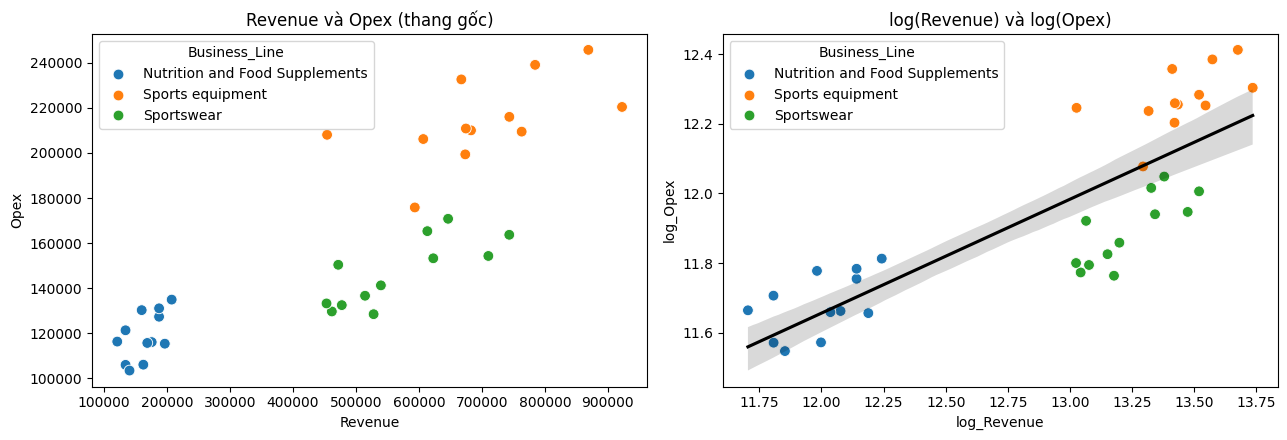

In [ ]:
pl_log = pd.DataFrame({
    "log_Revenue": np.log(pl["Revenue"]),
    "log_Opex": np.log(pl["Opex"]),
    "Business_Line": pl["Business_Line"]})

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

sns.scatterplot(data=pl, x="Revenue", y="Opex", hue="Business_Line", s=60, ax=ax[0])
ax[0].set_title("Revenue và Opex (thang gốc)")

sns.scatterplot(data=pl_log, x="log_Revenue", y="log_Opex", hue="Business_Line", s=60, ax=ax[1])
sns.regplot(data=pl_log, x="log_Revenue", y="log_Opex", scatter=False, color="black", ax=ax[1])
ax[1].set_title("log(Revenue) và log(Opex)")

plt.tight_layout(); plt.show()

**b. Kiểm tra giả định hồi quy**

In [ ]:
import statsmodels.api as sm
from scipy.stats import shapiro
from statsmodels.stats.diagnostic import het_breuschpagan

# Biến đổi logarit
pl_log = pl[(pl["Revenue"] > 0) & (pl["Opex"] > 0)].copy()
pl_log["log_Revenue"] = np.log(pl_log["Revenue"])
pl_log["log_Opex"] = np.log(pl_log["Opex"])

# Mô hình hồi quy log-log, sai số chuẩn robust HC3
X = sm.add_constant(pl_log["log_Revenue"])
model = sm.OLS(pl_log["log_Opex"], X).fit(cov_type="HC3")

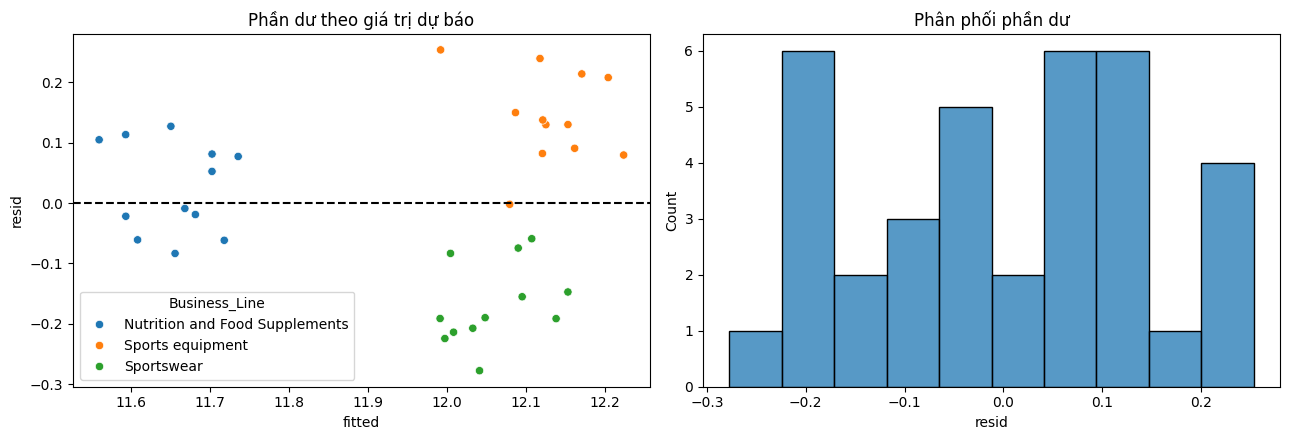

,0
Shapiro-Wilk p-value,0.158
Breusch-Pagan p-value,0.011


In [ ]:
pl_log["fitted"] = model.fittedvalues
pl_log["resid"] = model.resid

# Trực quan hoá phần dư
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

sns.scatterplot(data=pl_log, x="fitted", y="resid", hue="Business_Line", ax=ax[0])
ax[0].axhline(0, color="black", ls="--")
ax[0].set_title("Phần dư theo giá trị dự báo")

sns.histplot(pl_log["resid"], bins=10, ax=ax[1])
ax[1].set_title("Phân phối phần dư")

plt.tight_layout()
plt.show()

# Kiểm định giả định
p_sw = shapiro(model.resid).pvalue
p_bp = het_breuschpagan(model.resid, model.model.exog)[1]

pd.Series({
    "Shapiro-Wilk p-value": f"{p_sw:.3f}",
    "Breusch-Pagan p-value": f"{p_bp:.3f}"
})

**c. Kiểm định giả thuyết**

**c.1. Kiểm định tương quan giữa Revenue và Opex**: sử dụng Spearman để đánh giá mức độ tương quan giữa hai biến.

In [ ]:
from scipy.stats import spearmanr

rs, p_rs = spearmanr(pl["Revenue"], pl["Opex"])
pd.Series({"Spearman": round(rs, 3), "p-value": f"{p_rs:.2e}"})

,0
Spearman,0.889
p-value,4.57e-13


**c.2. Kiểm định hệ số co giãn β trong mô hình hồi quy log-log**: Kiểm định H₀: β = 1 và H₁: β ≠ 1 để xác định Opex có tăng cùng tỷ lệ với Revenue hay không.

In [ ]:
b = model.params["log_Revenue"]
ci = model.conf_int().loc["log_Revenue"]
tt = model.t_test("log_Revenue = 1")

pd.Series({"Beta": round(b, 3),
           "CI 95%": f"[{ci.iloc[0]:.3f}; {ci.iloc[1]:.3f}]",
           "Thống kê (H0: β=1)": round(float(tt.statistic.item()), 2),
           "p-value": f"{float(tt.pvalue):.2e}",
           "R²": round(model.rsquared, 3)})

,0
Beta,0.327
CI 95%,[0.267; 0.387]
Thống kê (H0: β=1),-21.92
p-value,1.59e-106
R²,0.687
